# Project info
Link to paper: https://kdd.org/exploration_files/p20-Is_Less_Really_More.pdf \
Link to authors' github repo: https://github.com/kappakant/SLIM/tree/main

# Imports

In [ ]:
import pandas as pd

# Preprocessing
The authors' repository and paper don't show specifically how they split the data, and they work based off of loaded csv's that aren't anywhere in the repository and seem to have come from their computer or another source that can't be identified. Therefore, to make sure we are following their preprocessing, we simply loaded their train, test, and validation csv's for both datasets.

Aside from this, the only other preprocessing the paper states is converting all text to lowercase and removing paragraph separators '\n'.

In [ ]:
# Load the datasets

base_url = "https://raw.githubusercontent.com/kappakant/SLIM/main/dataset"

files = {
    "ReCOVery": {
        "train": f"{base_url}/ReCOVery/train_preprocessed.csv",
        "validation": f"{base_url}/ReCOVery/eval_preprocessed.csv",
        "test": f"{base_url}/ReCOVery/test_preprocessed.csv",
    },
    "Fake_And_Real_News": {
        "train": f"{base_url}/fake_and_real_news/train_preprocessed.csv",
        "validation": f"{base_url}/fake_and_real_news/eval_preprocessed.csv",
        "test": f"{base_url}/fake_and_real_news/test_preprocessed.csv",
    }
}

for dataset, paths in files.items():
  print(f"Dataset: {dataset}")
  for split, path in paths.items():
      print(f"Split: {split}")
      display(pd.read_csv(path).head())

In [ ]:
# Basic preprocessing

def preprocess_text(text):
    return str(text).replace("\n", " ").lower() # replace "\n" with " " because otherwise words would be merged on newlines

# Since ReCOVery and Fake_And_Real_News have different column names for their main text components ("text" vs. "merged_info"), I renamed both columns to "body" to make it simpler to work with.
def preprocess_recovery(path):
    df = pd.read_csv(path)
    df["text"] = df["text"].apply(preprocess_text)
    df = df.rename(columns={"text": "body"})
    df = df[["label", "body"]] # switch the order of the columns to be label, body so that both datasets are consistent with order
    return df

def preprocess_fake_and_real(path):
    df = pd.read_csv(path)
    df["merged_info"] = df["merged_info"].apply(preprocess_text)
    df = df.rename(columns={"merged_info": "body"})
    return df

preprocessed = {
    "ReCOVery": {
        "train": preprocess_recovery(files["ReCOVery"]["train"]),
        "validation": preprocess_recovery(files["ReCOVery"]["validation"]),
        "test": preprocess_recovery(files["ReCOVery"]["test"]),
    },
    "Fake_And_Real_News": {
        "train": preprocess_fake_and_real(files["Fake_And_Real_News"]["train"]),
        "validation": preprocess_fake_and_real(files["Fake_And_Real_News"]["validation"]),
        "test": preprocess_fake_and_real(files["Fake_And_Real_News"]["test"]),
    }
}

def display_preprocessed_data():
  for dataset, splits in preprocessed.items():
    print("=" * 20)
    print(f"Dataset: {dataset}")
    for split, df in splits.items():
        print("-" * 20)
        print(f"Split: {split}")
        display(df.head())

display_preprocessed_data()

In [ ]:
# Other checks

for dataset, splits in preprocessed.items():
  print("=" * 20)
  print(f"Dataset: {dataset}")

  for split, df in splits.items():
      print("-" * 20)
      print(f"Split: {split}")
      print("Rows:", len(df))
      print("Missing text:", df["body"].isna().sum())
      print("Duplicate articles:", df["body"].duplicated().sum())
      print("Label counts:")
      print(df["label"].value_counts().sort_index())



There are no missing values. Although there are some duplicate news articles, we do not remove them (or take any further preprocessing steps in general) because the authors did not say they did so. This is only for our own insight about the datasets.

IMPORTANT: The validation and test splits are swapped in the authors' code vs. what it is written in their paper, e.g. the paper says ReCOVery validation is 114 / 278 and test is 64 / 120 while the code is the other way around, as shown in the results above. We chose to follow what the code does.

# Baseline Model and Evaluation

The baseline model uses the complete article body as input.

Following the paper, XLNet-base is fine-tuned for fake-news classification. The model uses cross-entropy loss for classification and the Adam optimizer with a learning rate of 5 × 10^-5.

The model is evaluated using accuracy, macro-F1, and AUC on the validation and test sets.

In [ ]:
!pip install -q transformers sentencepiece accelerate

In [ ]:
import copy
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MODEL_NAME = "xlnet-base-cased"
MAX_LENGTH = 512
BATCH_SIZE = 4
EPOCHS = 3
LEARNING_RATE = 5e-5

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

In [ ]:
def prepare_dataset(dataset_name):
    train_df = preprocessed[dataset_name]["train"].copy()
    validation_df = preprocessed[dataset_name]["validation"].copy()
    test_df = preprocessed[dataset_name]["test"].copy()

    return train_df, validation_df, test_df


recovery_train, recovery_val, recovery_test = prepare_dataset(
    "ReCOVery"
)

fake_train, fake_val, fake_test = prepare_dataset(
    "Fake_And_Real_News"
)

In [ ]:
def encode_labels(train_df, validation_df, test_df):
    label_encoder = LabelEncoder()

    train_df = train_df.copy()
    validation_df = validation_df.copy()
    test_df = test_df.copy()

    train_df["label_encoded"] = label_encoder.fit_transform(
        train_df["label"]
    )

    validation_df["label_encoded"] = label_encoder.transform(
        validation_df["label"]
    )

    test_df["label_encoded"] = label_encoder.transform(
        test_df["label"]
    )

    return (
        train_df,
        validation_df,
        test_df,
        label_encoder
    )

In [ ]:
(
    recovery_train,
    recovery_val,
    recovery_test,
    recovery_label_encoder
) = encode_labels(
    recovery_train,
    recovery_val,
    recovery_test
)

(
    fake_train,
    fake_val,
    fake_test,
    fake_label_encoder
) = encode_labels(
    fake_train,
    fake_val,
    fake_test
)

print(
    "ReCOVery label mapping:",
    dict(
        zip(
            recovery_label_encoder.classes_,
            recovery_label_encoder.transform(
                recovery_label_encoder.classes_
            )
        )
    )
)

print(
    "Fake_And_Real_News label mapping:",
    dict(
        zip(
            fake_label_encoder.classes_,
            fake_label_encoder.transform(
                fake_label_encoder.classes_
            )
        )
    )
)

In [ ]:
class NewsDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["body"].astype(str).tolist()
        self.labels = dataframe["label_encoded"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        return {
            "text": self.texts[index],
            "labels": self.labels[index]
        }

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def create_dataloader(dataframe, shuffle=False):
    dataset = NewsDataset(dataframe)

    def collate_batch(batch):
        texts = [
            item["text"]
            for item in batch
        ]

        labels = torch.tensor(
            [
                item["labels"]
                for item in batch
            ],
            dtype=torch.long
        )

        encoded = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        encoded["labels"] = labels

        return encoded

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        collate_fn=collate_batch
    )

In [ ]:
def evaluate_xlnet(
    model,
    data_loader,
    dataset_name,
    split_name,
    model_name="XLNet Full-Text Baseline"
):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for batch in data_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            labels = batch["labels"]

            outputs = model(**batch)

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1].cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    print(
        f"\n{dataset_name} - "
        f"{model_name} - "
        f"{split_name}"
    )

    print("-" * 60)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1: {macro_f1:.4f}")
    print(f"AUC: {auc:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            all_labels,
            all_predictions
        )
    )

    return {
        "dataset": dataset_name,
        "model": model_name,
        "split": split_name,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "auc": auc,
        "labels": all_labels,
        "predictions": all_predictions,
        "probabilities": all_probabilities
    }

In [ ]:
def train_xlnet_baseline(
    train_df,
    validation_df,
    test_df,
    dataset_name
):
    train_loader = create_dataloader(
        train_df,
        shuffle=True
    )

    validation_loader = create_dataloader(
        validation_df,
        shuffle=False
    )

    test_loader = create_dataloader(
        test_df,
        shuffle=False
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    )

    model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_validation_f1 = -1
    best_model_state = None

    for epoch in range(EPOCHS):
        model.train()
        total_training_loss = 0

        for batch in train_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            optimizer.zero_grad()

            outputs = model(**batch)

            # XLNet returns cross-entropy loss
            loss = outputs.loss

            loss.backward()
            optimizer.step()

            total_training_loss += loss.item()

        average_training_loss = (
            total_training_loss / len(train_loader)
        )

        validation_results = evaluate_xlnet(
            model=model,
            data_loader=validation_loader,
            dataset_name=dataset_name,
            split_name=f"Validation - Epoch {epoch + 1}"
        )

        print(
            f"Average training loss: "
            f"{average_training_loss:.4f}"
        )

        if (
            validation_results["macro_f1"]
            > best_validation_f1
        ):
            best_validation_f1 = (
                validation_results["macro_f1"]
            )

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_model_state)

    final_validation_results = evaluate_xlnet(
        model=model,
        data_loader=validation_loader,
        dataset_name=dataset_name,
        split_name="Validation - Best Model"
    )

    test_results = evaluate_xlnet(
        model=model,
        data_loader=test_loader,
        dataset_name=dataset_name,
        split_name="Test"
    )

    return {
        "model": model,
        "tokenizer": tokenizer,
        "validation_results": final_validation_results,
        "test_results": test_results
    }

In [23]:
recovery_baseline = train_xlnet_baseline(
    recovery_train,
    recovery_val,
    recovery_test,
    "ReCOVery"
)

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.bias                    | UNEXPECTED | 
lm_loss.weight                  | UNEXPECTED | 
sequence_summary.summary.bias   | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



ReCOVery - XLNet Full-Text Baseline - Validation - Epoch 1
------------------------------------------------------------
Accuracy: 0.6522
Macro-F1: 0.3947
AUC: 0.9180

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        64
           1       0.65      1.00      0.79       120

    accuracy                           0.65       184
   macro avg       0.33      0.50      0.39       184
weighted avg       0.43      0.65      0.51       184

Average training loss: 0.5781


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - XLNet Full-Text Baseline - Validation - Epoch 2
------------------------------------------------------------
Accuracy: 0.6522
Macro-F1: 0.3947
AUC: 0.3128

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        64
           1       0.65      1.00      0.79       120

    accuracy                           0.65       184
   macro avg       0.33      0.50      0.39       184
weighted avg       0.43      0.65      0.51       184

Average training loss: 0.6079


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - XLNet Full-Text Baseline - Validation - Epoch 3
------------------------------------------------------------
Accuracy: 0.6522
Macro-F1: 0.3947
AUC: 0.7077

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        64
           1       0.65      1.00      0.79       120

    accuracy                           0.65       184
   macro avg       0.33      0.50      0.39       184
weighted avg       0.43      0.65      0.51       184

Average training loss: 0.6553


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - XLNet Full-Text Baseline - Validation - Best Model
------------------------------------------------------------
Accuracy: 0.6522
Macro-F1: 0.3947
AUC: 0.9180

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        64
           1       0.65      1.00      0.79       120

    accuracy                           0.65       184
   macro avg       0.33      0.50      0.39       184
weighted avg       0.43      0.65      0.51       184



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - XLNet Full-Text Baseline - Test
------------------------------------------------------------
Accuracy: 0.7117
Macro-F1: 0.4242
AUC: 0.9372

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.01      0.02       114
           1       0.71      1.00      0.83       278

    accuracy                           0.71       392
   macro avg       0.86      0.50      0.42       392
weighted avg       0.80      0.71      0.59       392



In [24]:
fake_real_baseline = train_xlnet_baseline(
    fake_train,
    fake_val,
    fake_test,
    "Fake_And_Real_News"
)

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.bias                    | UNEXPECTED | 
lm_loss.weight                  | UNEXPECTED | 
sequence_summary.summary.bias   | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Fake_And_Real_News - XLNet Full-Text Baseline - Validation - Epoch 1
------------------------------------------------------------
Accuracy: 0.4800
Macro-F1: 0.3243
AUC: 0.8961

Classification Report:
              precision    recall  f1-score   support

           0       0.48      1.00      0.65       551
           1       0.00      0.00      0.00       597

    accuracy                           0.48      1148
   macro avg       0.24      0.50      0.32      1148
weighted avg       0.23      0.48      0.31      1148

Average training loss: 0.5457


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Fake_And_Real_News - XLNet Full-Text Baseline - Validation - Epoch 2
------------------------------------------------------------
Accuracy: 0.5192
Macro-F1: 0.3746
AUC: 0.8699

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.04      0.07       551
           1       0.52      0.96      0.68       597

    accuracy                           0.52      1148
   macro avg       0.50      0.50      0.37      1148
weighted avg       0.51      0.52      0.39      1148

Average training loss: 0.7085

Fake_And_Real_News - XLNet Full-Text Baseline - Validation - Epoch 3
------------------------------------------------------------
Accuracy: 0.4800
Macro-F1: 0.3243
AUC: 0.8614

Classification Report:
              precision    recall  f1-score   support

           0       0.48      1.00      0.65       551
           1       0.00      0.00      0.00       597

    accuracy                           0.48      1148
   macro avg       0.24

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Fake_And_Real_News - XLNet Full-Text Baseline - Validation - Best Model
------------------------------------------------------------
Accuracy: 0.5192
Macro-F1: 0.3746
AUC: 0.8699

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.04      0.07       551
           1       0.52      0.96      0.68       597

    accuracy                           0.52      1148
   macro avg       0.50      0.50      0.37      1148
weighted avg       0.51      0.52      0.39      1148


Fake_And_Real_News - XLNet Full-Text Baseline - Test
------------------------------------------------------------
Accuracy: 0.4909
Macro-F1: 0.3659
AUC: 0.8779

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.05      0.08       592
           1       0.49      0.96      0.65       557

    accuracy                           0.49      1149
   macro avg       0.53      0.50      0.37      1149
weighted avg

In [25]:
baseline_results = pd.DataFrame([
    recovery_baseline["validation_results"],
    recovery_baseline["test_results"],
    fake_real_baseline["validation_results"],
    fake_real_baseline["test_results"]
])

baseline_results[
    [
        "dataset",
        "model",
        "split",
        "accuracy",
        "macro_f1",
        "auc"
    ]
]

,dataset,model,split,accuracy,macro_f1,auc
0,ReCOVery,XLNet Full-Text Baseline,Validation - Best Model,0.652174,0.394737,0.917969
1,ReCOVery,XLNet Full-Text Baseline,Test,0.711735,0.424241,0.937240
2,Fake_And_Real_News,XLNet Full-Text Baseline,Validation - Best Model,0.519164,0.374560,0.869871
3,Fake_And_Real_News,XLNet Full-Text Baseline,Test,0.490862,0.365942,0.877884


In [26]:
def display_xlnet_confusion_matrix(
    results,
    dataset_name
):
    labels = results["labels"]
    predictions = results["predictions"]

    matrix = confusion_matrix(
        labels,
        predictions
    )

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=matrix
    )

    display_plot.plot(cmap="Blues")

    plt.title(
        f"{dataset_name} - XLNet Baseline"
    )

    plt.show()

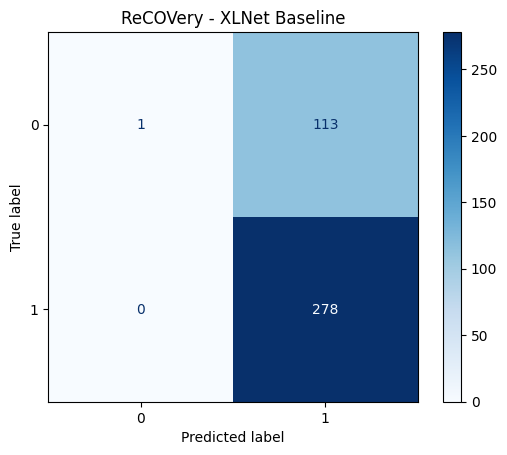

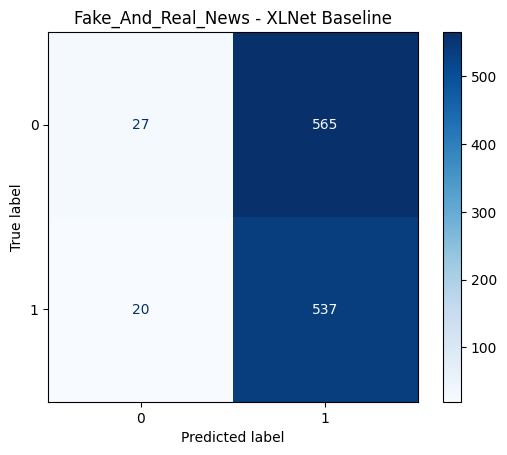

In [27]:
display_xlnet_confusion_matrix(
    recovery_baseline["test_results"],
    "ReCOVery"
)

display_xlnet_confusion_matrix(
    fake_real_baseline["test_results"],
    "Fake_And_Real_News"
)

# SLIM Metadata

Attaching the metadata to the authors' preprocessed csv's

In [ ]:
recovery_url = "https://raw.githubusercontent.com/apurvamulay/ReCOVery/master/dataset/recovery-news-data.csv"
recovery_original = pd.read_csv(recovery_url)

fake_real_url = "https://raw.githubusercontent.com/GeorgeMcIntire/fake_real_news_dataset/main/fake_and_real_news_dataset.csv"
fake_real_original = pd.read_csv(fake_real_url)

display(recovery_original.head())
display(fake_real_original.head())

In [ ]:
print("========== ReCOVery ==========")
print("Columns:", recovery_original.columns.tolist())
print("Shape:", recovery_original.shape)
print("Missing values:")
print(recovery_original[["body_text", "title", "author", "reliability"]].isna().sum())

print("\n========== Fake and Real News ==========")
print("Columns:", fake_real_original.columns.tolist())
print("Shape:", fake_real_original.shape)
print("Missing values:")
print(fake_real_original[["text", "title", "label"]].isna().sum())

In [ ]:
# similar to preprocess_text
def preprocess_body(text):
  if pd.isna(text):
    return ""
  text = str(text).replace("\n", " ").lower()
  text = " ".join(text.split())
  return text

In [ ]:
# copies of the original for the purpose of matching the metadata

recovery_matching = recovery_original.copy()
fake_real_matching = fake_real_original.copy()

recovery_matching["body_key"] = recovery_matching["body_text"].apply(preprocess_body)
fake_real_matching["body_key"] = fake_real_matching["text"].apply(preprocess_body)

display(recovery_matching[["body_text", "body_key"]].head(3))
display(fake_real_matching[["text", "body_key"]].head(3))

In [ ]:
for name, df in [("ReCOVery", recovery_matching), ("Fake and Real News", fake_real_matching)]:
    print(f"\n========== {name} ==========")
    print("Total records:", len(df))
    print("Unique bodies:", df["body_key"].nunique())
    print("Duplicate body groups:", df["body_key"].duplicated(keep=False).sum())


print("\nUnique records for title metadata")
for name, df in [("ReCOVery", recovery_matching), ("Fake and Real News", fake_real_matching)]:
    title_counts = df.groupby("body_key")["title"].nunique()

    print(f"\n========== {name} ==========")
    print("Body groups with one title:", (title_counts == 1).sum())
    print("Body groups with multiple titles:", (title_counts > 1).sum())


print("\nUnique records for author metadata")
recovery_with_authors = recovery_matching[
    recovery_matching["author"].notna() &
    recovery_matching["author"].str.strip().ne("[]")]

author_counts = recovery_with_authors.groupby("body_key")["author"].nunique()

print(f"\n========== ReCOVery ==========")
print("Body groups with one author:", (author_counts == 1).sum())
print("Body groups with multiple authors:", (author_counts > 1).sum())

In [ ]:
# recovery title metadata recovery
# only keep records that have one unique title
recovery_title_counts = (
    recovery_matching
    .dropna(subset=["title"])
    .groupby("body_key")["title"]
    .nunique()
)

recovery_valid_title_keys = recovery_title_counts[recovery_title_counts == 1].index

# retrieve body keys that have one unique title, and drop duplicates and na values
recovery_title_lookup = (
    recovery_matching[
        recovery_matching["body_key"].isin(recovery_valid_title_keys)
        ][["body_key", "title"]]
        .dropna(subset=["title"])
        .drop_duplicates(subset=["body_key"])
        .copy()
)

print("Unique bodies with unambiguous titles:", len(recovery_title_lookup))
display(recovery_title_lookup.head())


In [ ]:
# fake and real title metadata recovery
# only keep records that have one unique title
fake_real_title_counts = (
    fake_real_matching
    .dropna(subset=["title"])
    .groupby("body_key")["title"]
    .nunique()
)

fake_real_valid_title_keys = fake_real_title_counts[fake_real_title_counts == 1].index

fake_real_title_lookup = (
    fake_real_matching[
        fake_real_matching["body_key"].isin(fake_real_valid_title_keys)
        ][["body_key", "title"]]
        .dropna(subset=["title"])
        .drop_duplicates(subset=["body_key"])
        .copy()
)

print("Unique bodies with unambiguous titles:", len(fake_real_title_lookup))
display(fake_real_title_lookup.head())

In [ ]:
# recovery author metadata recovery
# only keep records that have one unique author entry, and exclude both [] and na since both are no author
recovery_author_counts = (
    recovery_matching[
        recovery_matching["author"].notna()
        & recovery_matching["author"].str.strip().ne("[]")]
        .groupby("body_key")["author"]
        .nunique()
)

recovery_valid_author_keys = recovery_author_counts[recovery_author_counts == 1].index

recovery_author_lookup = (
    recovery_matching[
        recovery_matching["body_key"].isin(recovery_valid_author_keys)
        & recovery_matching["author"].notna()
        & recovery_matching["author"].str.strip().ne("[]")
        ][["body_key", "author"]]
        .drop_duplicates(subset=["body_key"])
        .copy()
)

print("Unique bodies with unambiguous authors:", len(recovery_author_lookup))
display(recovery_author_lookup.head())

In [ ]:
print("ReCOVery title attachment\n")

recovery_title_data = {}

for split, df in preprocessed["ReCOVery"].items():
    github_split = df.copy()
    github_split["body_key"] = github_split["body"].apply(preprocess_body)

    # attach titles
    merged = github_split.merge(
        recovery_title_lookup,
        on="body_key",
        how="left",
        validate="many_to_one"
    )

    # keep only records that received a title
    matched = merged.dropna(subset=["title"]).copy()

    # remove the temporary matching column
    matched = matched.drop(columns=["body_key"])

    recovery_title_data[split] = matched

    print(
        f"{split}: {len(matched)}/{len(df)} records matched "
        f"({len(matched) / len(df):.2%})"
    )

In [ ]:
print("Fake and Real title attachment\n")
fake_real_title_data = {}

for split, df in preprocessed["Fake_And_Real_News"].items():
    github_split = df.copy()
    github_split["body_key"] = github_split["body"].apply(preprocess_body)

    # attach titles
    merged = github_split.merge(
        fake_real_title_lookup,
        on="body_key",
        how="left",
        validate="many_to_one"
    )

    # keep only records that received a title
    matched = merged.dropna(subset=["title"]).copy()

    # remove the temporary matching column
    matched = matched.drop(columns=["body_key"])

    fake_real_title_data[split] = matched

    print(
        f"{split}: {len(matched)}/{len(df)} records matched "
        f"({len(matched) / len(df):.2%})"
    )

In [ ]:
print("ReCOVery author attachment\n")
recovery_author_data = {}

for split, df in preprocessed["ReCOVery"].items():
    github_split = df.copy()
    github_split["body_key"] = github_split["body"].apply(preprocess_body)

    # attach authors
    merged = github_split.merge(
        recovery_author_lookup,
        on="body_key",
        how="left",
        validate="many_to_one"
    )

    # keep only records that received authors
    matched = merged.dropna(subset=["author"]).copy()

    # remove the temporary matching column
    matched = matched.drop(columns=["body_key"])

    recovery_author_data[split] = matched

    print(
        f"{split}: {len(matched)}/{len(df)} records matched "
        f"({len(matched) / len(df):.2%})"
    )

In [ ]:
metadata_experiments = {
    "ReCOVery Title": (recovery_title_data, "title", "ReCOVery"),
    "ReCOVery Author": (recovery_author_data, "author", "ReCOVery"),
    "Fake and Real Title": (fake_real_title_data, "title", "Fake_And_Real_News")
}

In [ ]:
# validate the splits are still balanced
for experiment, (data, metadata_column, original_dataset) in metadata_experiments.items():

    print(f"\n========== {experiment} ==========")

    for split, df in data.items():
        original_df = preprocessed[original_dataset][split]

        print(f"\n{split}:")
        print("Columns correct:",
              df.columns.tolist() == ["label", "body", metadata_column])
        print("Missing metadata:", df[metadata_column].isna().sum())
        print("Rows preserved correctly:", len(df) <= len(original_df))
        print("Original split size:", len(original_df))
        print("Matched split size:", len(df))
        print(f"Matched split size (%): {len(df) / len(original_df):.2%}")

Train/test/validation splits are all preserved well.

In [ ]:
# validate the classes are still balanced
for experiment, (data, metadata_column, original_dataset) in metadata_experiments.items():

    print(f"\n========== {experiment} ==========")

    for split, matched_df in data.items():
        original_df = preprocessed[original_dataset][split]

        # original dataset
        original_counts = original_df["label"].value_counts().sort_index()
        # dataset after matching metadata
        matched_counts = matched_df["label"].value_counts().reindex(
            original_counts.index, fill_value=0
        )

        comparison = pd.DataFrame({
            "Original Count": original_counts,
            "Original %": (
                original_counts / len(original_df) * 100
            ).round(2),
            "Matched Count": matched_counts,
            "Matched %": (
                matched_counts / len(matched_df) * 100
            ).round(2),
            "Retention %": (
                matched_counts / original_counts * 100
            ).round(2)
        })

        print(f"\n--- {split} ---")
        display(comparison)


All class balance looks good except for ReCOVery author. This can affect the results of the author metadata experiment.

Actual Experiment